# Challenge 1: datos y análisis exploratorio

Tu primera responsabilidad es preparar una fuente de datos confiable para el proyecto de clasificación de vinos.

**Entrada:** `data/raw/wine.csv`  
**Salidas:** `data/processed/train.csv`, `data/processed/test.csv` y `artifacts/data_contract.json`

> El conjunto de test se crea aquí, pero no debe explorarse ni utilizarse después del split.

## Objetivos

- cargar y validar datos externos;
- identificar problemas básicos de calidad;
- crear un split reproducible y estratificado;
- realizar EDA únicamente sobre entrenamiento;
- guardar datos y metadatos para la siguiente etapa.

In [6]:
# Configuración Colab: carpeta compartida en Drive para los 3 notebooks
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/semana6/data/raw', exist_ok=True)
os.chdir('/content/drive/MyDrive/semana6')

# Descargar el dataset del repositorio del curso
!wget -q -O data/raw/wine.csv https://raw.githubusercontent.com/EAFIT-IA/si3003-artificial-intelligence/main/notebooks/lecture6/challenge/data/wine.csv
print(os.listdir('data/raw'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['wine.csv']


In [7]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

np.random.seed(42)
plt.rcParams["figure.figsize"] = (7, 4)

In [8]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga y profiling

In [9]:
# TODO 1
DATA_PATH = RAW_DATA_DIR / "wine.csv"
df = pd.read_csv(DATA_PATH)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [10]:
# TODO 2 — profiling
print("Forma:", df.shape)
print("\nTipos:\n", df.dtypes.value_counts())
print("\nNulos totales:", df.isna().sum().sum())
print("Duplicados:", df.duplicated().sum())
print("\nDistribución de target:\n", df["target"].value_counts().sort_index())

Forma: (178, 14)

Tipos:
 float64    13
int64       1
Name: count, dtype: int64

Nulos totales: 0
Duplicados: 0

Distribución de target:
 target
0    59
1    71
2    48
Name: count, dtype: int64


**Conclusión de calidad:**

> Describe brevemente qué encontraste y qué decisión tomaste.

178 filas y 14 columnas, todas numéricas. No hay nulos ni duplicados. Las clases están algo desbalanceadas (59 / 71 / 48), por eso el split es estratificado. No fue necesario limpiar nada.

## 2. Split train/test

In [11]:
# TODO 3 — split
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["target"], random_state=RANDOM_STATE
)

In [12]:
# Verificación del split
assert len(train_df) + len(test_df) == len(df)
assert set(train_df.index).isdisjoint(set(test_df.index))
print("Train:", train_df.shape)
print("Test:", test_df.shape)

Train: (142, 14)
Test: (36, 14)


## 3. EDA sobre entrenamiento

Incluye:

- distribución de clases;
- distribuciones o boxplots de variables relevantes;
- correlaciones;
- tres hallazgos que puedan influir en el modelado.

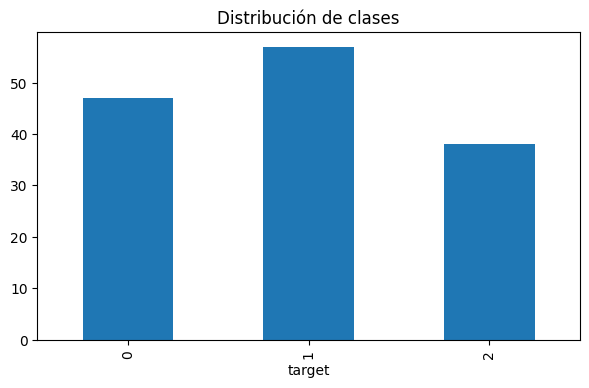

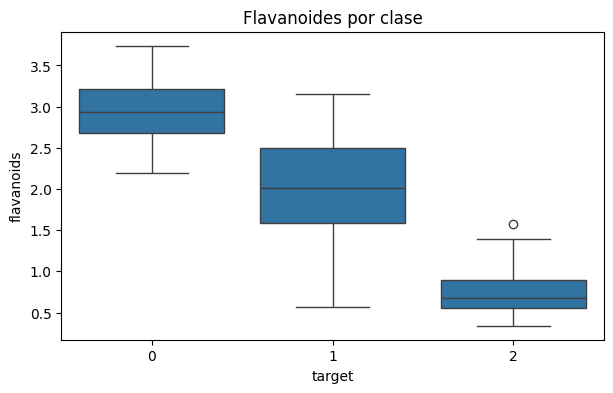

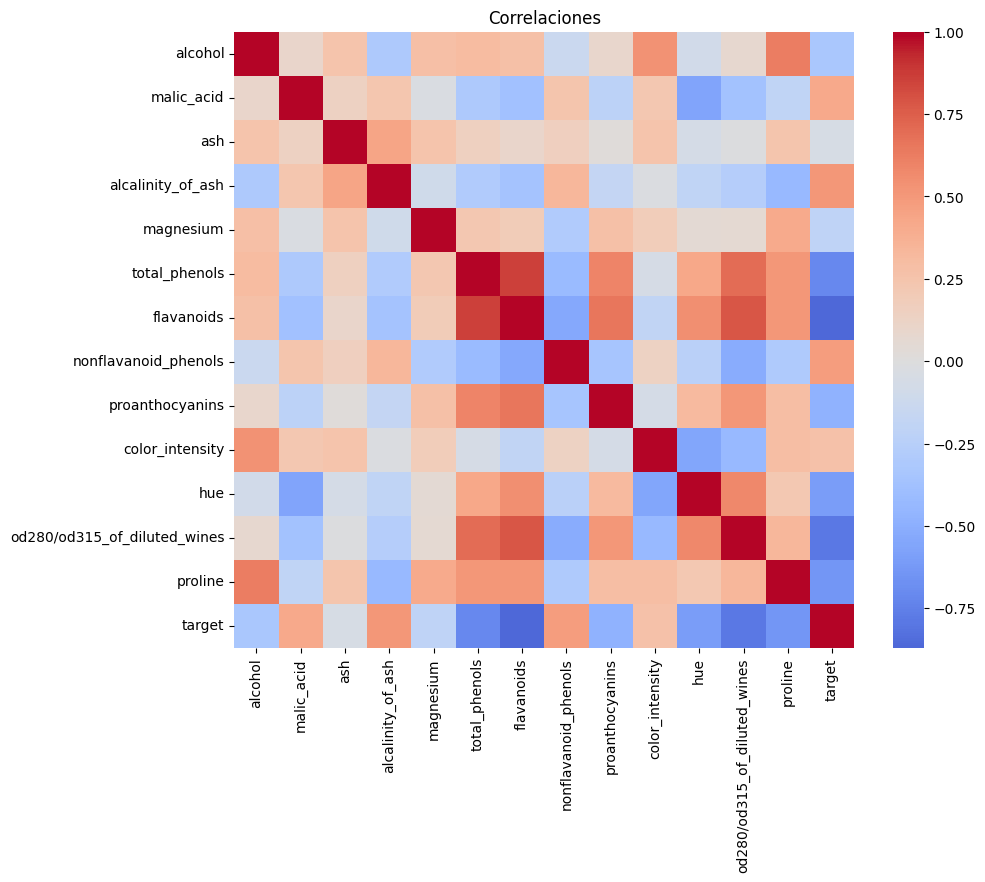

In [13]:
# TODO 4 — EDA solo con train_df
train_df["target"].value_counts().sort_index().plot(kind="bar", title="Distribución de clases")
plt.show()

sns.boxplot(data=train_df, x="target", y="flavanoids")
plt.title("Flavanoides por clase")
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(train_df.corr(), cmap="coolwarm", center=0)
plt.title("Correlaciones")
plt.show()

**Hallazgos:**

1. Las clases están moderadamente desbalanceadas; la clase 2 es la más pequeña.
2. flavanoids separa muy bien las clases (correlación -0.87 con target), igual que
   od280/od315 y total_phenols: serán variables muy útiles.
3. Las escalas son muy distintas (proline llega a ~1500 y hue a ~1.7), así que
   conviene escalar los datos para modelos como regresión logística o KNN.

## 4. Persistencia de datos y contrato

In [14]:
# TODO 5 — guardar salidas
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)
train_df.to_csv(PROCESSED_DATA_DIR / "train.csv", index=False)
test_df.to_csv(PROCESSED_DATA_DIR / "test.csv", index=False)

contract = {
    "target": "target",
    "features": [c for c in train_df.columns if c != "target"],
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
}
with open(ARTIFACTS_DIR / "data_contract.json", "w") as f:
    json.dump(contract, f, indent=2)

In [15]:
# Verificación de entrega
assert (PROCESSED_DATA_DIR / "train.csv").exists()
assert (PROCESSED_DATA_DIR / "test.csv").exists()
assert (ARTIFACTS_DIR / "data_contract.json").exists()
print("Challenge 1 completado.")

Challenge 1 completado.


## Checklist

- [ ] Cargué el CSV desde `data/raw`.
- [ ] Revisé calidad y distribución de la clase.
- [ ] Realicé un split estratificado.
- [ ] No exploré el conjunto de test.
- [ ] Guardé los tres artefactos requeridos.